In [1]:
import numpy as np
from pathlib import Path
import pandas as pd
import sys
sys.path.insert(1, '../../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,Radar
from util.overshoots import local_safety, critical_parameter, OS_model, k_risk

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr

from matplotlib.colors import LinearSegmentedColormap
import colorcet as cc
import seaborn as sns

font = {'size':10}
mpl.rc('font', **font)

### Data_processing to get to df_TEs, T_lims, betas, q_c, q_r and the interaction matrices A

In [3]:
%run Data_processing.py

# Simulations

## Baseline for OAT

In [4]:
baselines  = ['ssp119', 'ssp534-over', 'CurPol_OS_1.5C']
temps = [df[b].to_numpy() for b in baselines]

In [6]:
### BASELINE SIMULATIONS
D_bs = []
for temp in temps:
    years = np.arange(1850,1850+len(temp))
    no_years = len(years)
    # Modifying collapse probabilities for each year according to each scenario
    p_c = np.ones((no_years,len(df_TEs)))
    p_c *= q_c
    
    p_r = np.ones((no_years,len(df_TEs)))
    p_r *= q_r
    
    for t in range(no_years):
        p_c[t,:] *= temp_response(temp[t], T_lim, betas)
        p_r[t,:] *= (1-temp_response(temp[t], T_lim, betas))
    
    D_baseline = np.zeros((len_sample,len(df_TEs),no_years))
    for r in range(len_sample):
        for t in range(1,no_years):
            D_baseline[r,:,t] = environmental_update(D_baseline[r,:,t-1],A[r],pc=p_c[t,:],pr=p_r[t,:])
    D_bs.append(D_baseline)

In [8]:
D_bs[0].shape

(500, 9, 451)

In [9]:
TR_bs = []
for D in D_bs:
    d_nr = np.delete(D,6,axis=1)
    TR_bs.append(k_risk(d_nr,1,axis=1))

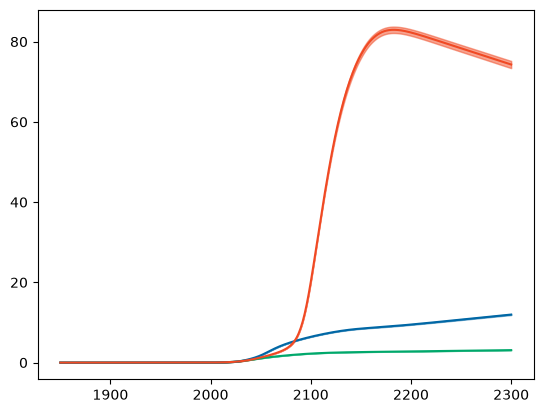

In [18]:
fig,ax=plt.subplots()
colors = ['#00A86B', '#0067A5', '#F04923']
for i in range(3):
    ax.fill_between(years,
                    (TR_bs[i].mean(axis=0)-TR_bs[i].std(axis=0))*100, 
                    (TR_bs[i].mean(axis=0)+TR_bs[i].std(axis=0))*100, color=colors[i],alpha=0.5)
    ax.plot(years,TR_bs[i].mean(axis=0)*100,color=colors[i])

In [21]:
for i in range(3):
    print(str(100*TR_bs[i][:,-1].mean()) + r'$\pm$' + str(100*TR_bs[i][:,-1].std()))

3.108357814481343$\pm$0.009286389308956169
11.972337966238$\pm$0.11819361659932065
74.29908566487352$\pm$0.898797070829108


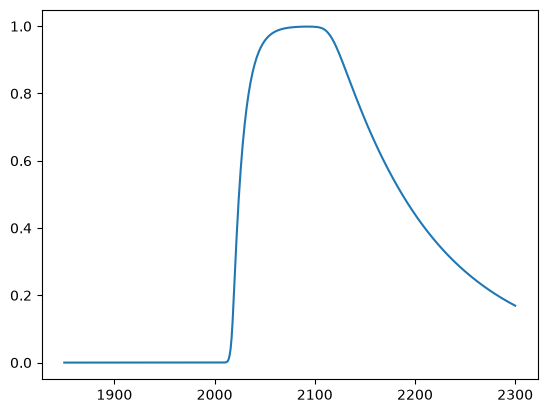

In [13]:
plt.plot(years,D_bs[0].mean(axis=0)[6])

## Ensemble

In [13]:
folder = '../../../Data/PROVIDE 2025/fair_temperatures/'
scenarios = os.listdir(folder)
print(scenarios)

['scen_ModAct nz 2120 decline -16500.csv', 'scen_LD_NZGHG.csv', 'scen_ssp534-over.csv', 'scen_Neg.csv', 'scen_CurPol.csv', 'scen_Ren_NZCO2.csv', 'scen_GS.csv', 'scen_Neg_NZGHG.csv', 'scen_SP_NZGHG.csv', 'scen_LD.csv', 'scen_GS_NZGHG.csv', 'scen_SP.csv', 'scen_Neg nz 2100 decline -17000.csv', 'scen_Ref_1p5.csv', 'scen_CurPol nz 2120 decline -23800.csv', 'scen_ModAct nz 2120 decline -23000.csv', 'scen_Ren.csv', 'scen_ModAct.csv', 'scen_ssp119.csv']


In [14]:
baselines = ['ssp119','ssp534-over','CurPol nz 2120 decline -23800']
temps = [pd.read_csv(folder+'scen_%s.csv'%baseline).set_index('year').to_numpy().T for baseline in baselines]

In [15]:
pcs = [np.ones(list(temps[k].shape)+[len(df_TEs)])*q_c.reshape((1,1,len(df_TEs))) for k in range(3)]
prs = [np.ones(list(temps[k].shape)+[len(df_TEs)])*q_r.reshape((1,1,len(df_TEs))) for k in range(3)]

for k in range(3):
    no_runs, no_years = temps[k].shape
    sigma = temp_response(temps[k].reshape(no_runs, no_years,1),
                          T_lim.reshape(1,1,9),
                          betas.reshape(1,1,9))
    pcs[k] *= sigma
    prs[k] *= 1-sigma

Given the number of samples across interaction matrices (500) AND the number of ensemble runs (2237),

we find it better to save only summary statistics (across 500x2237 flattened) namely:
- mean
- std
- median
- 0.1 / 0.9 quantile
- 0.25 / 0.75 quantile

In [36]:
for k in range(3):
    D_mean = np.zeros([temps[k].shape[1],len(df_TEs)])
    D_std = np.zeros([temps[k].shape[1],len(df_TEs)])
    D_quants = np.zeros([5, temps[k].shape[1],len(df_TEs)]) # [0.1,0.25,0.5,0.75,0.9] quantiles

    T_mean = np.zeros([temps[k].shape[1]])
    T_std = np.zeros([temps[k].shape[1]])
    T_quants = np.zeros([5, temps[k].shape[1]]) # [0.1,0.25,0.5,0.75,0.9] quantiles
    
    no_runs, no_years = temps[k].shape
    
    D_t = np.zeros([500,no_runs,9]) # snapshots of D
    T_t = k_risk(np.delete(D_t,6,axis=-1),1,axis=2) # aggregate risk
    for t in tqdm.tqdm(range(no_years)):
        D_mean[t,:] = D_t.mean(axis=(0,1)) # saving mean
        D_std[t,:] = D_t.std(axis=(0,1)) # saving std
        D_quants[:,t,:] = np.quantile(D_t, [0.1,0.25,0.5,0.75,0.9],axis=(0,1))

        T_mean[t] = T_t.mean() # saving mean
        T_std[t] = T_t.std() # saving std
        T_quants[:,t] = np.quantile(T_t, [0.1,0.25,0.5,0.75,0.9])
        
        for er in range(no_runs):
            for r in range(500):
                D_t[r,er,:] = environmental_update(D_t[r,er,:],A[r],
                                                   pc=pcs[k][er,t,:],
                                                   pr=prs[k][er,t,:])
        T_t = k_risk(np.delete(D_t,6,axis=-1),1,axis=2)
                
    data_folder = '../../../Data/Simulations/Overshoots/'
    if k<2:
        data_folder += baselines[k]+'/'
    else:
        data_folder += 'CurPol_OS_1.5C/'
    
    data_folder += 'Ensemble/'
    if not os.path.isdir(data_folder):
        os.mkdir(data_folder)
    
    np.savetxt(data_folder+'mean.csv',D_mean)
    np.savetxt(data_folder+'std.csv',D_std)
    np.savetxt(data_folder+'T_mean.csv',T_mean)
    np.savetxt(data_folder+'T_std.csv',T_std)
    for i,p in enumerate([10,25,50,75,90]):
        np.savetxt(data_folder+'q%s.csv'%p,D_quants[i,:,:])
        np.savetxt(data_folder+'T_q%s.csv'%p,T_quants[i,:])

100%|███████████████████████████████████████| 451/451 [1:03:26<00:00,  8.44s/it]


In [7]:
data_folder = '../../../Data/Simulations/Overshoots/'
if k<2:
    data_folder += baselines[k]+'/'
else:
    data_folder += 'CurPol_OS_1.5C/'

data_folder += 'Ensemble/'
if not os.path.isdir(data_folder):
    os.mkdir(data_folder)

np.savetxt(data_folder+'mean.csv',D_mean)
np.savetxt(data_folder+'std.csv',D_std)
for i,p in enumerate([10,25,50,75,90]):
    np.savetxt(data_folder+'q%s.csv'%p,D_quants[i,:,:])

# Plotting

In [4]:
data_folder = '../../../Data/Simulations/Overshoots/'
scenarios = ['ssp119','ssp534-over','CurPol_OS_1.5C']
D_means = [np.loadtxt(data_folder+'%s/Ensemble/mean.csv'%s) for s in scenarios]
D_stds = [np.loadtxt(data_folder+'%s/Ensemble/std.csv'%s) for s in scenarios]
D_qs = [np.array([np.loadtxt(data_folder+'%s/Ensemble/q%s.csv'%(s,q)) 
                  for q in [10,25,50,75,90]]) 
        for s in scenarios]

T_means = [np.loadtxt(data_folder+'%s/Ensemble/T_mean.csv'%s) for s in scenarios]
T_stds = [np.loadtxt(data_folder+'%s/Ensemble/T_std.csv'%s) for s in scenarios]
T_qs = [np.array([np.loadtxt(data_folder+'%s/Ensemble/T_q%s.csv'%(s,q)) 
                  for q in [10,25,50,75,90]]) 
        for s in scenarios]

TEs=df_TEs.index.values

In [22]:
D_qs[0].shape

(5, 451, 9)

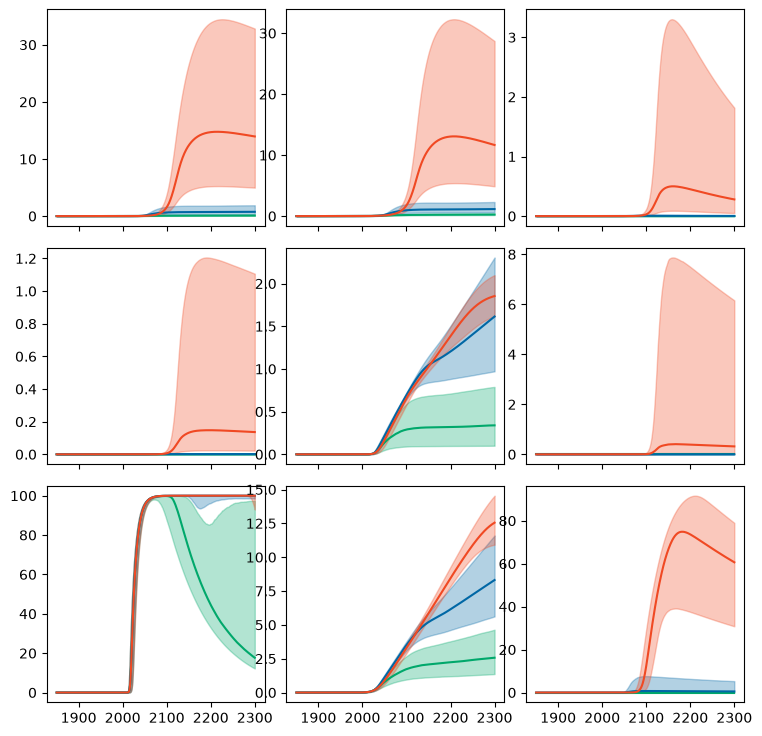

In [38]:
colors=['#00A86B', '#0067A5', '#F04923']
years=np.arange(1850,2301)
fig,axs=plt.subplots(ncols=3,nrows=3,figsize=(9,9),sharex=True,sharey=False)
fig.subplots_adjust(hspace=0.1,wspace=0.1)

for i,te in enumerate(TEs):
    for k,s in enumerate(scenarios):
        axs[i//3,i%3].fill_between(years, D_qs[k][1,:,i]*100, D_qs[k][3,:,i]*100,color=colors[k],alpha=0.3)
        axs[i//3,i%3].plot(years, D_qs[k][2,:,i]*100,label=s,ls='-',color=colors[k])
        # axs[i//3,i%3].plot(np.arange(1850,2301), D_means[k][:,i]*100,label=s,ls=':',color=colors[k])
    # axs[i//3,i%3].legend(title=te)

In [40]:
D_qs[0].shape

(5, 451, 9)

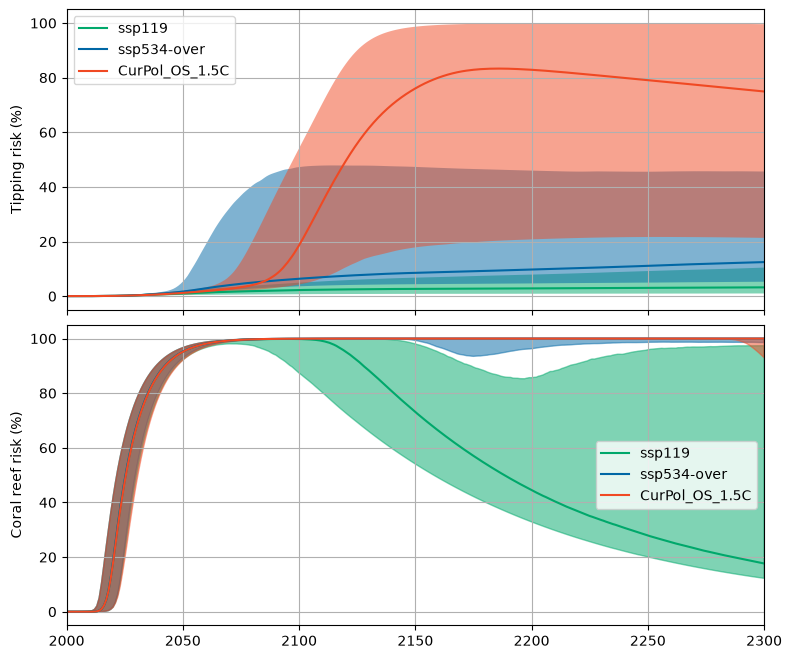

In [59]:
fig,axs=plt.subplots(nrows=2,figsize=(9,8),sharex=True,sharey=True)
fig.subplots_adjust(hspace=0.05)
axs[0].set_xlim(2000,2300)
# axs[0].set_ylim(-2,102)

colors=['#00A86B', '#0067A5', '#F04923']
for k,s in enumerate(scenarios):
    # axs[0].plot(years,T_means[k]*100,color=colors[k],ls='-')
    # axs[0].fill_between(years,
    #                     100*(T_means[k]-T_stds[k]),
    #                     100*(T_means[k]+T_stds[k]),color=colors[k],alpha=.5)
    axs[0].fill_between(years,
                        100*(T_qs[k][0,:]),
                        100*(T_qs[k][4,:]),color=colors[k],alpha=.5,edgecolor=None)
    axs[0].plot(years,T_qs[k][2,:]*100,color=colors[k],ls='-',label=s)
    
    axs[1].fill_between(years,
                        100*(D_qs[k][1,:,6]),
                        100*(D_qs[k][3,:,6]),color=colors[k],alpha=.5)
    axs[1].plot(years,D_qs[k][2,:,6]*100,color=colors[k],ls='-',label=s)

axs[0].legend()#title='Tipping risk')
axs[1].legend()#title='Coral reef risk')

axs[0].set_ylabel('Tipping risk (%)')
axs[1].set_ylabel('Coral reef risk (%)')

for i in range(2):
    axs[i].grid()
    # axs[i].set_ylabel('Risk (%)')

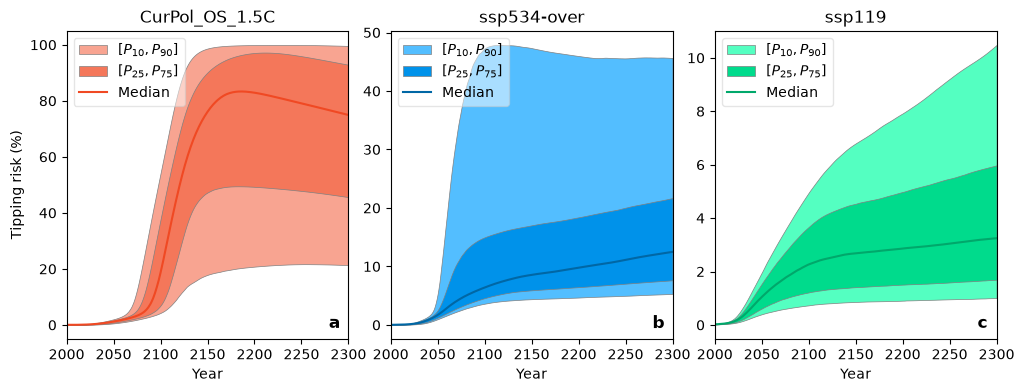

In [57]:
fig,axs=plt.subplots(ncols=3,sharex=True,sharey=False,figsize=(12,4))
fig.subplots_adjust(wspace=0.15,hspace=0.0)

axs[0].set_ylabel('Tipping risk (%)')
# axs[0].set_ylim(-2,102)
axs[0].set_xlim(2000,2300)

years=np.arange(1850,2301)
colors=['#00A86B', '#0067A5', '#F04923']
lightening_factors = [0.75,0.8,0.85][::-1]
for k,s in enumerate(scenarios):
    ax=axs[2-k]
    ax.set_title(s)
    ax.set_xlabel('Year')
    ax.fill_between(years,
                    100*(T_qs[k][0,:]),
                    100*(T_qs[k][4,:]),color=lighten_color(colors[k],0.5),edgecolor='gray',lw=0.5,
                    label=r'$[P_{10},P_{90}]$')
    ax.fill_between(years,
                    100*(T_qs[k][1,:]),
                    100*(T_qs[k][3,:]),color=lighten_color(colors[k],lightening_factors[k]),edgecolor='gray',lw=0.5,
                    label=r'$[P_{25},P_{75}]$')
    ax.plot(years,T_qs[k][2,:]*100,color=colors[k],ls='-',label='Median')
    ax.legend(framealpha=0.5,loc='upper left')
    ax.annotate('cba'[k], (0.95,0.05), ha='center',va='center',xycoords='axes fraction',weight='bold',fontsize=12)

fig.savefig('../../../Figures/Overshoots/Submission/Ensemble_3_panels.pdf',bbox_inches='tight',
            dpi=300,format='pdf')

In [35]:
T_qs[0].shape

(5, 451)